In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from  sklearn.datasets import fetch_california_housing
# load dataset
california=fetch_california_housing()
#printing keys
print("Dataset Keys:",california.keys())


Dataset Keys: dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])


In [4]:
#creating data frame
dataset=pd.DataFrame(california.data,columns=california.feature_names)
print(dataset.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  


In [5]:
#adding dependent/target feature(price)
dataset['Price']=california.target
print(dataset.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  


In [7]:
#dividing into dependent and independent features
X=pd.DataFrame(california.data,columns=california.feature_names) #independent
Y=california.target #dependent

In [8]:
#train-test split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.3,random_state=42)


In [9]:
#Standardizing the dataset
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
#fit and transform training data ,only transform testing data
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

how to inverse transform data back to original values
original_X_train=scaler.inverse_transform(X_train)

In [10]:
#Model training(Linear Regression)
from sklearn.linear_model import LinearRegression
regression=LinearRegression()
regression.fit(X_train,Y_train)

LinearRegression()

In [11]:
#HYperparameter Tuning/model checking via Cross-validation
from sklearn.model_selection import cross_val_score
mse_scores=cross_val_score(regression,X_train,Y_train,scoring='neg_mean_squared_error',cv=5)
print("MSE Scores for each fold:",mse_scores)
print("Mean MSE score:",np.mean(mse_scores))

MSE Scores for each fold: [-0.54787556 -0.500835   -0.52045639 -0.51612252 -0.54883741]
Mean MSE score: -0.5268253746355748


In [12]:
# doing prediction on test data
reg_pred=regression.predict(X_test)
print("predicted values:",reg_pred)

predicted values: [0.72604907 1.76743383 2.71092161 ... 2.07465531 1.57371395 1.82744133]


<function matplotlib.pyplot.show(close=None, block=None)>

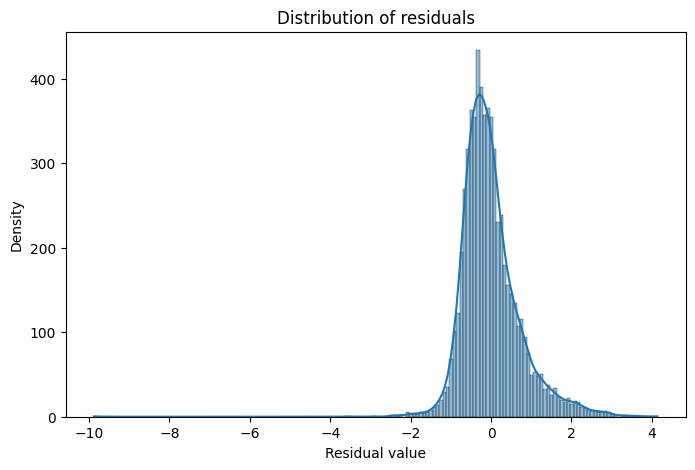

In [13]:
#visualizing the prediction performance (Residual analysis)
#plotting the difference betweeen truth and predictions using distribution plot
residuals=Y_test-reg_pred
plt.figure(figsize=(8,5))
sns.histplot(residuals,kde=True)
plt.title("Distribution of residuals")
plt.xlabel("Residual value")
plt.ylabel("Density")
plt.show

In [14]:
#performance metrics(R-squared Score)
from sklearn.metrics import r2_score
score=r2_score(Y_test,reg_pred)
print("R-squared Score:",score)

R-squared Score: 0.5957702326061664


In [1]:
#Ridge regression implementation
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
ridge = Ridge()
parameters_ridge = {'alpha': [1e-15, 1e-10, 1e-8, 1e-3, 1e-2, 1, 5, 10, 20, 30, 35, 40, 45, 50, 55, 100]}

In [15]:
#GridSearchCV with 5-fold cross-validation
ridge_regressor = GridSearchCV(ridge, parameters_ridge, scoring='neg_mean_squared_error', cv=5)
ridge_regressor.fit(X_train, Y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [1e-15, 1e-10, 1e-08, 0.001, 0.01, 1, 5, 10,
                                   20, 30, 35, 40, 45, 50, 55, 100]},
             scoring='neg_mean_squared_error')

In [16]:
# Display best parameters and the cross-validation score
print("RIDGE REGRESSION RESULTS")
print("Best Alpha parameter found:", ridge_regressor.best_params_)
print("Best Mean MSE Score:", abs(ridge_regressor.best_score_))

RIDGE REGRESSION RESULTS
Best Alpha parameter found: {'alpha': 5}
Best Mean MSE Score: 0.5268179966861514


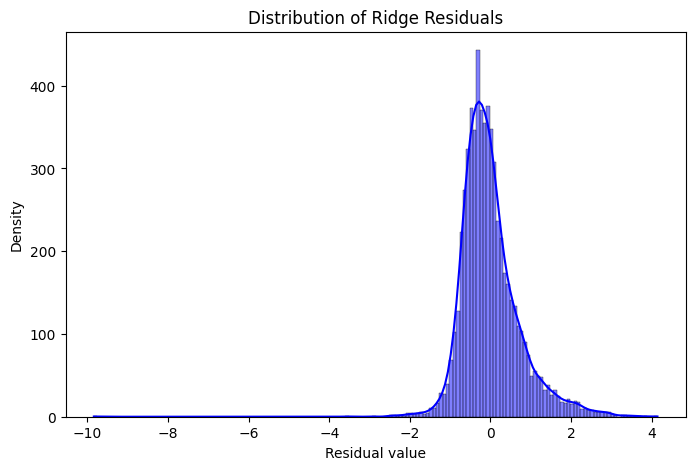

In [17]:
# Predict on test data
ridge_pred = ridge_regressor.predict(X_test)
# Plotting the Ridge residuals
ridge_residuals = Y_test - ridge_pred
plt.figure(figsize=(8, 5))
sns.histplot(ridge_residuals, kde=True, color='blue')
plt.title("Distribution of Ridge Residuals")
plt.xlabel("Residual value")
plt.ylabel("Density")
plt.show()

In [18]:
# Calculate Ridge R-squared Score
ridge_score = r2_score(Y_test, ridge_pred)
print("Ridge R-squared Score:", ridge_score)

Ridge R-squared Score: 0.5958597389519957


In [19]:
#LASSO REGRESSION IMPLEMENTATION(L1 Regularization)
from sklearn.linear_model import Lasso
lasso = Lasso(max_iter=100000)
parameters_lasso = {'alpha': [1e-15, 1e-10, 1e-8, 1e-3, 1e-2, 1, 5, 10, 20, 30, 35, 40, 45, 50, 55, 100]}

In [20]:
# Setup GridSearchCV for Lasso
lasso_regressor = GridSearchCV(lasso, parameters_lasso, scoring='neg_mean_squared_error', cv=5)
lasso_regressor.fit(X_train, Y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.286e+01, tolerance: 1.570e+00
  model = cd_fast.enet_coordinate_descent(


GridSearchCV(cv=5, estimator=Lasso(max_iter=100000),
             param_grid={'alpha': [1e-15, 1e-10, 1e-08, 0.001, 0.01, 1, 5, 10,
                                   20, 30, 35, 40, 45, 50, 55, 100]},
             scoring='neg_mean_squared_error')

In [21]:
# Display best parameters and cross-validation score
print("\n--- LASSO REGRESSION RESULTS ---")
print("Best Alpha parameter found:", lasso_regressor.best_params_)
print("Best Mean MSE Score:", abs(lasso_regressor.best_score_))


--- LASSO REGRESSION RESULTS ---
Best Alpha parameter found: {'alpha': 0.001}
Best Mean MSE Score: 0.526481690640263


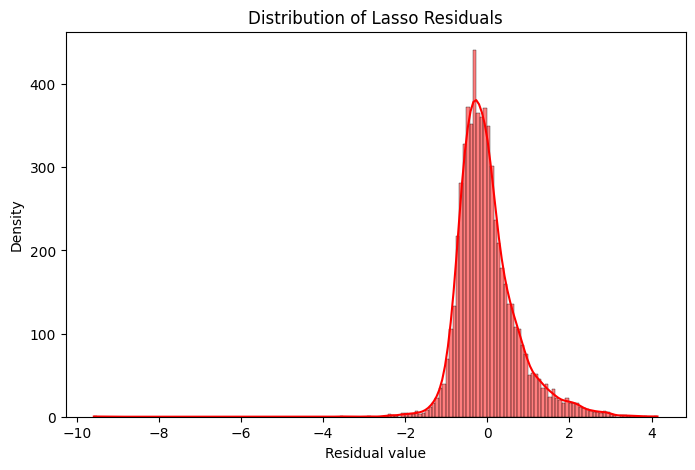

In [22]:
# Predict on test data
lasso_pred = lasso_regressor.predict(X_test)

# Plotting the Lasso residuals
lasso_residuals = Y_test - lasso_pred
plt.figure(figsize=(8, 5))
sns.histplot(lasso_residuals, kde=True, color='red')
plt.title("Distribution of Lasso Residuals")
plt.xlabel("Residual value")
plt.ylabel("Density")
plt.show()

In [23]:
# Calculate Lasso R-squared Score
lasso_score = r2_score(Y_test, lasso_pred)
print("Lasso R-squared Score:", lasso_score)

Lasso R-squared Score: 0.5963975777208825
